In [1]:
# problem statement 2 

In [2]:
# 1B. Implementing Feedforward Neural Network (FNN) with Keras and TensorFlow 
# for the classification of Fashion MNIST dataset using below steps: 
# a. Import the necessary packages 
# b. Load the training and testing data (CIFAR10) 
# c. Define the network architecture using Keras 
# d. Train the model using SGD 
# e. Evaluate the network 
# f. Plot the training loss and accuracy

In [3]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 

In [6]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input , Flatten , Dense
from tensorflow.keras.optimizers import SGD

In [13]:
# Load Data 
test_data = pd.read_csv('./LP IV Updated Datasets/FNN and CNN/Fashion MNIST/fashion-mnist_test.csv')
train_data = pd.read_csv('./LP IV Updated Datasets/FNN and CNN/Fashion MNIST/fashion-mnist_train.csv' )

In [48]:
# seperate out the image and label 
y_train = train_data.iloc[:,0].values
y_test = test_data.iloc[:,0].values

x_train =train_data.iloc[:,1:].values
x_test = test_data.iloc[:,1:].values

In [49]:
print("Training data Shape : ", x_train.shape)
print("testing data shape : ", x_test.shape)

Training data Shape :  (60000, 784)
testing data shape :  (10000, 784)


In [50]:
#normalixe the data 
x_train = x_train / 255.0
x_test = x_test / 255.0


In [51]:
model = Sequential([
    Input(shape=(784 ,)),
    Flatten(),
    Dense(128 , activation='relu'),
    Dense(64 , activation='relu'),
    Dense(10 , activation='softmax')
])

In [52]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [53]:
# d. Train the model using SGD 
model.compile(
    optimizer=SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [54]:
histroy = model.fit(
    x_train, 
    y_train,
    epochs=11, 
    batch_size = 32 , 
    validation_split= 0.2
)

Epoch 1/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.7479 - loss: 0.7633 - val_accuracy: 0.8143 - val_loss: 0.5503
Epoch 2/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8209 - loss: 0.5144 - val_accuracy: 0.8278 - val_loss: 0.5040
Epoch 3/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8370 - loss: 0.4659 - val_accuracy: 0.8425 - val_loss: 0.4686
Epoch 4/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8442 - loss: 0.4385 - val_accuracy: 0.8422 - val_loss: 0.4542
Epoch 5/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8533 - loss: 0.4179 - val_accuracy: 0.8414 - val_loss: 0.4490
Epoch 6/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8587 - loss: 0.4027 - val_accuracy: 0.8588 - val_loss: 0.4100
Epoch 7/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8621 - loss: 0.3906 - val_accuracy: 0.8593 - val_loss: 0.4071
Epoch 8/11
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8647 - loss: 0.3803 -

In [55]:
# e. Evaluate the network 
test_loss , test_accuracy = model.evaluate( x_test , y_test )


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8749 - loss: 0.3609


In [56]:
print("Training losss : ", test_loss)
print("testing loss : " ,test_accuracy)

Training losss :  0.36092326045036316
testing loss :  0.8748999834060669


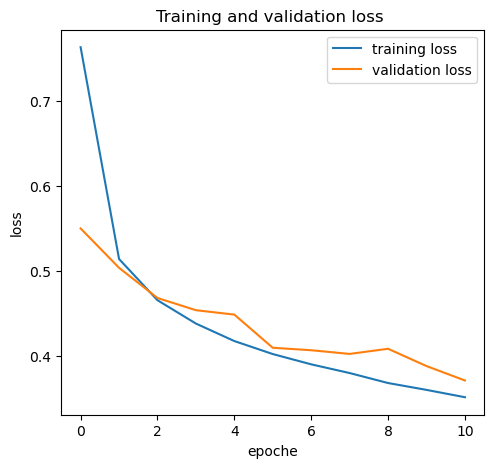

In [57]:
# f. Plot the training loss and accuracy
# plot loss
plt.figure(figsize=( 12 , 5 ))
plt.subplot( 1, 2, 1)
plt.plot(histroy.history['loss'] , label='training loss ')
plt.plot(histroy.history['val_loss'] , label='validation loss')
plt.title( "Training and validation loss ")
plt.xlabel('epoche')
plt.ylabel('loss')
plt.legend()

In [58]:
# p-lot accuracy 

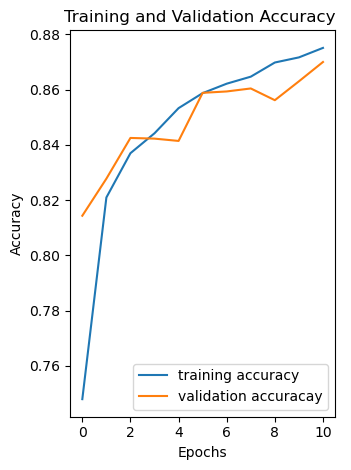

In [59]:
plt.subplot( 1,2,2 )
plt.plot(histroy.history['accuracy'] , label='training accuracy')
plt.plot(histroy.history['val_accuracy'] , label='validation accuracay')
plt.title("Training and Validation Accuracy ")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()